In [14]:
from pathlib import Path
import csv, json, sqlite3, tempfile
import os
import pandas as pd
from IPython.display import display
from collections import Counter, defaultdict
import matplotlib.pyplot as plt

candidates = [Path('../data/msd_strike.json'), Path('msd_strike.json')]
SOURCE = next((p.resolve() for p in candidates if p.exists()), None)
if SOURCE is None:
    raise FileNotFoundError('Could not find data/msd_strike.json')
OUT_DIR = SOURCE.parent
ORIGINALS_CSV = OUT_DIR / 'original_tweets.csv'
NODES_CSV = OUT_DIR / 'retweet_network_nodes.csv'
EDGES_CSV = OUT_DIR / 'retweet_network_edges.csv'
EVENTS_CSV = OUT_DIR / 'retweet_events.csv'
print(f'Source: {SOURCE} ({SOURCE.stat().st_size / 1e9:.2f} GB)')
print(f'Output folder: {OUT_DIR}')

Source: C:\Users\oskar\OneDrive\Documents\Kool\Uppsala\S3\Mining of Social Data\Mining-of-Social-Data\data\msd_strike.json (4.42 GB)
Output folder: C:\Users\oskar\OneDrive\Documents\Kool\Uppsala\S3\Mining of Social Data\Mining-of-Social-Data\data


## Task 1: Explore the raw data file

Before building anything we check what the file contains. Reading all 4.4 GB just to look at fields would be slow, so this cell parses a **systematic sample** (every 20th line) and reports, for every field, how often it is present, plus a few completeness checks. Percentages are therefore estimates from the sample.

In [15]:
SAMPLE_EVERY = 20                     # parse every 20th line: takes seconds instead of minutes
field_stats, examples = Counter(), {}
metric_nonzero, metric_names = Counter(), set()
ref_types, langs, sensitive = Counter(), Counter(), Counter()
first_original = first_retweet = earliest = latest = None
sample_n = originals_in_sample = total_lines = 0

with SOURCE.open('r', encoding='utf-8') as f:
    for i, line in enumerate(f):
        total_lines = i + 1
        if i % SAMPLE_EVERY or not line.strip():
            continue
        tweet = json.loads(line); sample_n += 1
        for key, value in tweet.items():
            field_stats[key] += 1; examples.setdefault(key, value)
            if isinstance(value, dict):                      # also list the sub-fields, e.g. entities.hashtags
                for sub, subvalue in value.items():
                    field_stats[f'{key}.{sub}'] += 1; examples.setdefault(f'{key}.{sub}', subvalue)
        refs = tweet.get('referenced_tweets') or []
        kinds = {r.get('type') for r in refs}
        ref_types[', '.join(sorted(kinds)) or 'none (original tweet)'] += 1
        langs[tweet.get('lang')] += 1
        sensitive[tweet.get('possibly_sensitive')] += 1
        stamp = tweet.get('created_at') or ''
        if stamp:
            earliest = stamp if earliest is None else min(earliest, stamp)
            latest = stamp if latest is None else max(latest, stamp)
        if not kinds & {'retweeted', 'quoted'}:
            originals_in_sample += 1
            for name, value in (tweet.get('public_metrics') or {}).items():
                metric_names.add(name)
                if value: metric_nonzero[name] += 1

print(f'{total_lines:,} lines in the file; explored a sample of {sample_n:,} tweets (every {SAMPLE_EVERY}th line).')
print(f'Period covered by the sample (UTC): {earliest} to {latest}\n')

field_table = pd.DataFrame([{'field': k, 'present_%': round(100 * n / sample_n, 1),
                             'example': str(examples[k]).replace('\n', ' ')[:70]}
                            for k, n in sorted(field_stats.items())])
print('Fields (sub-fields shown as parent.child):'); display(field_table)
print('Tweet types in the sample:'); display(pd.Series(ref_types, name='tweets').sort_values(ascending=False).to_frame())
print('Most common language codes in the sample:'); display(pd.Series(langs, name='tweets').sort_values(ascending=False).head(10).to_frame())
print('possibly_sensitive values:', dict(sensitive))
print('Share of original-tweet records with a non-zero metric (%):')
display((pd.Series(metric_nonzero).reindex(sorted(metric_names), fill_value=0) / originals_in_sample * 100).round(1).rename('non-zero %').to_frame())
profile_like = {'username', 'name', 'description', 'verified', 'location', 'followers_count', 'user', 'users', 'includes'}
print('User-profile fields present in the file:', sorted(k for k in field_stats if k.split('.')[0] in profile_like) or 'none')

2,170,868 lines in the file; explored a sample of 108,544 tweets (every 20th line).
Period covered by the sample (UTC): 2019-09-20T00:04:14.000Z to 2019-09-27T23:59:57.000Z

Fields (sub-fields shown as parent.child):


,field,present_%,example
0,attachments,18.7,{'media_keys': ['7_1175045062796947456']}
1,attachments.media_keys,18.7,['7_1175045062796947456']
2,author_id,100.0,1252004226
3,context_annotations,82.9,"[{'domain': {'id': '10', 'name': 'Person', 'de..."
4,conversation_id,100.0,1174836630437470208
5,created_at,100.0,2019-09-20T00:04:14.000Z
6,edit_history_tweet_ids,100.0,['1174836630437470208']
7,entities,99.6,"{'mentions': [{'start': 3, 'end': 15, 'usernam..."
8,entities.annotations,62.0,"[{'start': 98, 'end': 112, 'probability': 0.62..."
9,entities.cashtags,0.0,"[{'start': 267, 'end': 274, 'tag': 'WaigMe'}]"


Tweet types in the sample:


,tweets
retweeted,92198
none (original tweet),10958
quoted,2995
replied_to,2325
"quoted, replied_to",68


Most common language codes in the sample:


,tweets
en,80199
es,6621
de,5402
it,3715
fr,3519
qme,2591
pt,1010
qht,742
in,519
sv,506


possibly_sensitive values: {False: 107867, True: 677}
Share of original-tweet records with a non-zero metric (%):


,non-zero %
bookmark_count,3.0
impression_count,0.0
like_count,59.3
quote_count,10.0
reply_count,19.9
retweet_count,36.8


User-profile fields present in the file: none


### What the file contains and what we may use later

Each line is one tweet in the Twitter/X API v2 format. The field table above shows which fields are present and how complete they are. The main groups are:

| Field | Meaning |
|---|---|
| `id`, `author_id` |
| `created_at` | timestamp (UTC) |
| `text`, `lang` | tweet text and language code (`qme` and `qht` are Twitter's codes for media-only and hashtag-only tweets, not real languages) |
| `entities` | parsed hashtags, mentions, URLs, annotations |
| `context_annotations` | Twitter's own topic labels, present only on some tweets | 
| `public_metrics` | retweet, reply, like, quote (and bookmark, impression) counts | 
| `referenced_tweets` | type (`retweeted`, `quoted`, `replied_to`) and id of the tweet this one refers to |
| `conversation_id` | id of the first tweet in the thread |
| `possibly_sensitive` | Twitter's content flag |

## Build the datasets

One streaming pass over the source creates `original_tweets.csv`, `retweet_events.csv`, the edge table and the node table, and also collects the counts for the summary below (unique users, tweet types, dates, hours, hashtags). It takes several minutes because every record is parsed; progress is printed every 100,000 records.

In [16]:
fd, db_name = tempfile.mkstemp(prefix='msd_retweet_index_', suffix='.sqlite')
os.close(fd)
db_path = Path(db_name)
db = sqlite3.connect(db_path)
db.execute('PRAGMA journal_mode=OFF'); db.execute('PRAGMA synchronous=OFF')
db.executescript('''
CREATE TABLE tweets(tweet_id TEXT PRIMARY KEY, author_id TEXT);
CREATE TABLE retweets(retweet_id TEXT, source_account_id TEXT, target_tweet_id TEXT, created_at TEXT, mention_author_id TEXT);
CREATE TABLE authors(author_id TEXT PRIMARY KEY, tweet_count INTEGER, first_seen TEXT, last_seen TEXT);
''')
AUTHOR_UPSERT = '''INSERT INTO authors VALUES (?,1,?,?) ON CONFLICT(author_id) DO UPDATE SET
    tweet_count=tweet_count+1, first_seen=MIN(first_seen, excluded.first_seen), last_seen=MAX(last_seen, excluded.last_seen)'''
tweet_batch, retweet_batch, author_batch = [], [], []
records_seen = originals_written = retweets_seen = 0
quotes_seen = replies_seen = 0
type_counts = Counter()
daily_counts = defaultdict(Counter)
hour_of_day_counts = defaultdict(Counter)
hashtag_counts = Counter()
columns = ['tweet_id','author_id','created_at','text','lang','conversation_id','reply_to_tweet_id','retweet_count','reply_count','like_count','quote_count','possibly_sensitive','hashtags']
with SOURCE.open('r', encoding='utf-8') as source, ORIGINALS_CSV.open('w', encoding='utf-8-sig', newline='') as out:
    writer = csv.DictWriter(out, fieldnames=columns); writer.writeheader()
    for line in source:
        if not line.strip(): continue
        tweet = json.loads(line); records_seen += 1
        tweet_id, author_id = str(tweet.get('id') or ''), str(tweet.get('author_id') or '')
        created_at = tweet.get('created_at') or ''
        if tweet_id and author_id:
            tweet_batch.append((tweet_id, author_id)); author_batch.append((author_id, created_at, created_at))
        refs = tweet.get('referenced_tweets') or []
        is_retweet = any(ref.get('type') == 'retweeted' for ref in refs)
        is_quote = any(ref.get('type') == 'quoted' for ref in refs)
        is_reply = any(ref.get('type') == 'replied_to' for ref in refs)
        category = 'retweets' if is_retweet else ('quotes' if is_quote else 'original_tweets')
        type_counts[category] += 1
        if is_quote: quotes_seen += 1
        if is_reply: replies_seen += 1
        if len(created_at) >= 13:
            daily_counts[created_at[:10]][category] += 1
            hour_of_day_counts[created_at[11:13]][category] += 1
        entities = tweet.get('entities') or {}
        tweet_tags = []
        for hashtag in entities.get('hashtags') or []:
            tag = (hashtag.get('tag') or '').casefold()
            if tag: hashtag_counts[tag] += 1; tweet_tags.append(tag)
        # a native retweet starts with "RT @user:"; that first mention is the author of the retweeted tweet
        mentions = entities.get('mentions') or []
        rt_author = ''
        if (tweet.get('text') or '').startswith('RT @') and mentions and mentions[0].get('start') == 3:
            rt_author = str(mentions[0].get('id') or '')
        for ref in refs:
            if ref.get('type') == 'retweeted' and tweet_id and author_id:
                retweet_batch.append((tweet_id, author_id, str(ref.get('id') or ''), created_at, rt_author)); retweets_seen += 1
        if not any(ref.get('type') in {'retweeted','quoted'} for ref in refs):
            m = tweet.get('public_metrics') or {}
            writer.writerow({'tweet_id':tweet_id,'author_id':author_id,'created_at':created_at, 'text':tweet.get('text') or '', 'lang':tweet.get('lang') or '', 'conversation_id':tweet.get('conversation_id') or '', 'reply_to_tweet_id':next((r.get('id','') for r in refs if r.get('type')=='replied_to'),''), 'retweet_count':m.get('retweet_count',''), 'reply_count':m.get('reply_count',''), 'like_count':m.get('like_count',''), 'quote_count':m.get('quote_count',''), 'possibly_sensitive':tweet.get('possibly_sensitive',''), 'hashtags':' '.join(dict.fromkeys(tweet_tags))})
            originals_written += 1
        if len(tweet_batch) >= 10000:
            db.executemany('INSERT OR REPLACE INTO tweets VALUES (?,?)', tweet_batch)
            db.executemany(AUTHOR_UPSERT, author_batch)
            db.executemany('INSERT INTO retweets VALUES (?,?,?,?,?)', retweet_batch); db.commit()
            tweet_batch.clear(); author_batch.clear(); retweet_batch.clear()
        if records_seen % 100000 == 0: print(f'Parsed {records_seen:,}; originals {originals_written:,}; retweets {retweets_seen:,}')
    if tweet_batch or retweet_batch:
        db.executemany('INSERT OR REPLACE INTO tweets VALUES (?,?)', tweet_batch)
        db.executemany(AUTHOR_UPSERT, author_batch)
        db.executemany('INSERT INTO retweets VALUES (?,?,?,?,?)', retweet_batch)
    db.commit()
db.execute('CREATE INDEX retweets_target_idx ON retweets(target_tweet_id)')

# one row per retweet with its target account: from the file if the original is present, else from the RT mention
db.execute('''CREATE TABLE ties AS
    SELECT r.retweet_id, r.created_at, r.source_account_id, r.target_tweet_id,
           COALESCE(t.author_id, NULLIF(r.mention_author_id, '')) AS target_account_id,
           CASE WHEN t.author_id IS NULL AND r.mention_author_id <> '' THEN 1 ELSE 0 END AS target_from_mention
    FROM retweets r LEFT JOIN tweets t ON t.tweet_id = r.target_tweet_id''')
db.commit()

with EVENTS_CSV.open('w', encoding='utf-8-sig', newline='') as out:
    w = csv.writer(out); w.writerow(['retweet_id','created_at','source_account_id','target_account_id','target_tweet_id','target_from_mention'])
    w.writerows(db.execute("SELECT retweet_id, created_at, source_account_id, COALESCE(target_account_id,''), target_tweet_id, target_from_mention FROM ties"))

edge_query = '''SELECT source_account_id, COALESCE(target_account_id,''),
        CASE WHEN target_account_id IS NULL THEN target_tweet_id ELSE '' END,
        COUNT(*), COUNT(DISTINCT target_tweet_id), SUM(target_from_mention), MIN(created_at), MAX(created_at)
    FROM ties
    GROUP BY source_account_id, COALESCE(target_account_id,''), CASE WHEN target_account_id IS NULL THEN target_tweet_id ELSE '' END
    ORDER BY 1, 2, 3'''
with EDGES_CSV.open('w', encoding='utf-8-sig', newline='') as out:
    w = csv.writer(out); w.writerow(['source_account_id','target_account_id','unresolved_target_tweet_id','retweet_count','distinct_tweets_retweeted','retweets_target_from_mention','first_retweeted_at','last_retweeted_at']); w.writerows(db.execute(edge_query))

node_query = '''WITH endpoints AS (
        SELECT source_account_id AS account_id FROM ties
        UNION SELECT target_account_id FROM ties WHERE target_account_id IS NOT NULL),
    sent AS (SELECT source_account_id AS account_id, COUNT(*) AS n FROM ties GROUP BY 1),
    received AS (SELECT target_account_id AS account_id, COUNT(*) AS n FROM ties WHERE target_account_id IS NOT NULL GROUP BY 1)
    SELECT e.account_id, COALESCE(a.tweet_count,0), COALESCE(a.first_seen,''), COALESCE(a.last_seen,''), COALESCE(s.n,0), COALESCE(v.n,0)
    FROM endpoints e
    LEFT JOIN authors a ON a.author_id = e.account_id
    LEFT JOIN sent s ON s.account_id = e.account_id
    LEFT JOIN received v ON v.account_id = e.account_id
    ORDER BY e.account_id'''
with NODES_CSV.open('w', encoding='utf-8-sig', newline='') as out:
    w = csv.writer(out); w.writerow(['account_id','tweets_in_source','first_seen','last_seen','retweets_sent','retweets_received']); w.writerows(db.execute(node_query))

# quality checks (useful for the datasheets)
checked, agree = db.execute('''SELECT COUNT(*), COALESCE(SUM(t.author_id = r.mention_author_id), 0) FROM retweets r
    JOIN tweets t ON t.tweet_id = r.target_tweet_id WHERE r.mention_author_id <> ''  ''').fetchone()
build_checks = {
    'records': records_seen,
    'distinct_tweet_ids': db.execute('SELECT COUNT(*) FROM tweets').fetchone()[0],
    'retweets': db.execute('SELECT COUNT(*) FROM ties').fetchone()[0],
    'target_from_file': db.execute('SELECT COUNT(*) FROM ties WHERE target_account_id IS NOT NULL AND target_from_mention = 0').fetchone()[0],
    'target_from_mention': db.execute('SELECT COUNT(*) FROM ties WHERE target_from_mention = 1').fetchone()[0],
    'target_unknown': db.execute('SELECT COUNT(*) FROM ties WHERE target_account_id IS NULL').fetchone()[0],
    'mention_vs_file_compared': checked, 'mention_vs_file_agree': agree,
}
user_count = db.execute('SELECT COUNT(*) FROM authors').fetchone()[0]
db.close(); db_path.unlink(missing_ok=True)
print(f'Finished: {records_seen:,} records, {originals_written:,} original tweets, {retweets_seen:,} retweets, {quotes_seen:,} quote tweets, {user_count:,} unique users.')
print(f'Created {ORIGINALS_CSV.name}, {EVENTS_CSV.name}, {EDGES_CSV.name} and {NODES_CSV.name}.')
print('\nQuality checks:')
print(f"  records without a usable id/author or duplicated ids: {records_seen - build_checks['distinct_tweet_ids']:,}")
print(f"  retweets with target author from the file: {build_checks['target_from_file']:,}, from the RT mention: {build_checks['target_from_mention']:,}, unknown: {build_checks['target_unknown']:,}")
if checked: print(f"  RT mention agrees with the file's author in {agree:,} of {checked:,} comparable retweets ({100 * agree / checked:.2f}%)")

Parsed 100,000; originals 13,032; retweets 84,161
Parsed 200,000; originals 26,689; retweets 167,938
Parsed 300,000; originals 40,131; retweets 251,944
Parsed 400,000; originals 50,646; retweets 339,350
Parsed 500,000; originals 60,525; retweets 427,442
Parsed 600,000; originals 69,295; retweets 516,663
Parsed 700,000; originals 77,010; retweets 607,152
Parsed 800,000; originals 83,704; retweets 698,851
Parsed 900,000; originals 91,899; retweets 788,803
Parsed 1,000,000; originals 100,858; retweets 877,831
Parsed 1,100,000; originals 109,579; retweets 966,994
Parsed 1,200,000; originals 119,559; retweets 1,054,579
Parsed 1,300,000; originals 132,735; retweets 1,138,143
Parsed 1,400,000; originals 149,473; retweets 1,215,695
Parsed 1,500,000; originals 166,706; retweets 1,294,019
Parsed 1,600,000; originals 183,529; retweets 1,373,524
Parsed 1,700,000; originals 201,413; retweets 1,451,783
Parsed 1,800,000; originals 218,359; retweets 1,530,810
Parsed 1,900,000; originals 233,596; retwe

### Add engagement attributes to the nodes

The node table from the build holds activity attributes (`tweets_in_source`, `first_seen`, `last_seen`, `retweets_sent`, `retweets_received`). This cell adds attributes describing how each account's **original** tweets were received: the number of original tweets and the sums of likes, replies, quotes and Twitter's own retweet counter on them (`retweet_counter_on_originals`; not the same as `retweets_received`, which counts retweets found in this file). Accounts without original tweets get 0. The cell can safely be re-run.

In [17]:
originals = pd.read_csv(ORIGINALS_CSV, usecols=['author_id','like_count','retweet_count','reply_count','quote_count'], dtype={'author_id':'string'})
engagement = originals.groupby('author_id').agg(
    original_tweets=('author_id', 'size'),
    likes_on_originals=('like_count', 'sum'),
    replies_on_originals=('reply_count', 'sum'),
    quotes_on_originals=('quote_count', 'sum'),
    retweet_counter_on_originals=('retweet_count', 'sum'))
nodes_table = pd.read_csv(NODES_CSV, dtype={'account_id':'string'})
nodes_table = nodes_table.drop(columns=[c for c in engagement.columns if c in nodes_table.columns])   # allows re-running
nodes_table = nodes_table.merge(engagement, left_on='account_id', right_index=True, how='left')
nodes_table[engagement.columns] = nodes_table[engagement.columns].fillna(0).astype('int64')
nodes_table.to_csv(NODES_CSV, index=False, encoding='utf-8-sig')
print(f'{len(nodes_table):,} nodes, columns: {list(nodes_table.columns)}')
display(nodes_table.head())

757,752 nodes, columns: ['account_id', 'tweets_in_source', 'first_seen', 'last_seen', 'retweets_sent', 'retweets_received', 'original_tweets', 'likes_on_originals', 'replies_on_originals', 'quotes_on_originals', 'retweet_counter_on_originals']


,account_id,tweets_in_source,first_seen,last_seen,retweets_sent,retweets_received,original_tweets,likes_on_originals,replies_on_originals,quotes_on_originals,retweet_counter_on_originals
0,1000000043833810945,1,2019-09-26T18:34:24.000Z,2019-09-26T18:34:24.000Z,1,0,0,0,0,0,0
1,1000001291945500672,1,2019-09-27T07:28:12.000Z,2019-09-27T07:28:12.000Z,0,541,1,2652,12,43,701
2,1000001515472474112,1,2019-09-21T08:51:35.000Z,2019-09-21T08:51:35.000Z,1,0,0,0,0,0,0
3,1000001979060576256,6,2019-09-20T17:36:30.000Z,2019-09-20T20:29:51.000Z,3,8,3,23,1,1,8
4,1000002497363283969,9,2019-09-23T01:23:42.000Z,2019-09-27T22:42:16.000Z,1,17,8,65,2,1,16


## Dataset summary and plots

Totals use all tweet records. Hashtags are counted case-insensitively. The date plot shows counts per UTC day; the hourly plot combines records by UTC hour of day (0–23).

,measure,count
0,Unique users,827292
1,All tweet records,2170868
2,Original tweets (includes replies),266350
3,Retweets,1845108
4,Quote tweets,59410
5,Replies (subset of originals),48083
6,Hashtag occurrences,3036321
7,Distinct hashtags (case-insensitive),84999


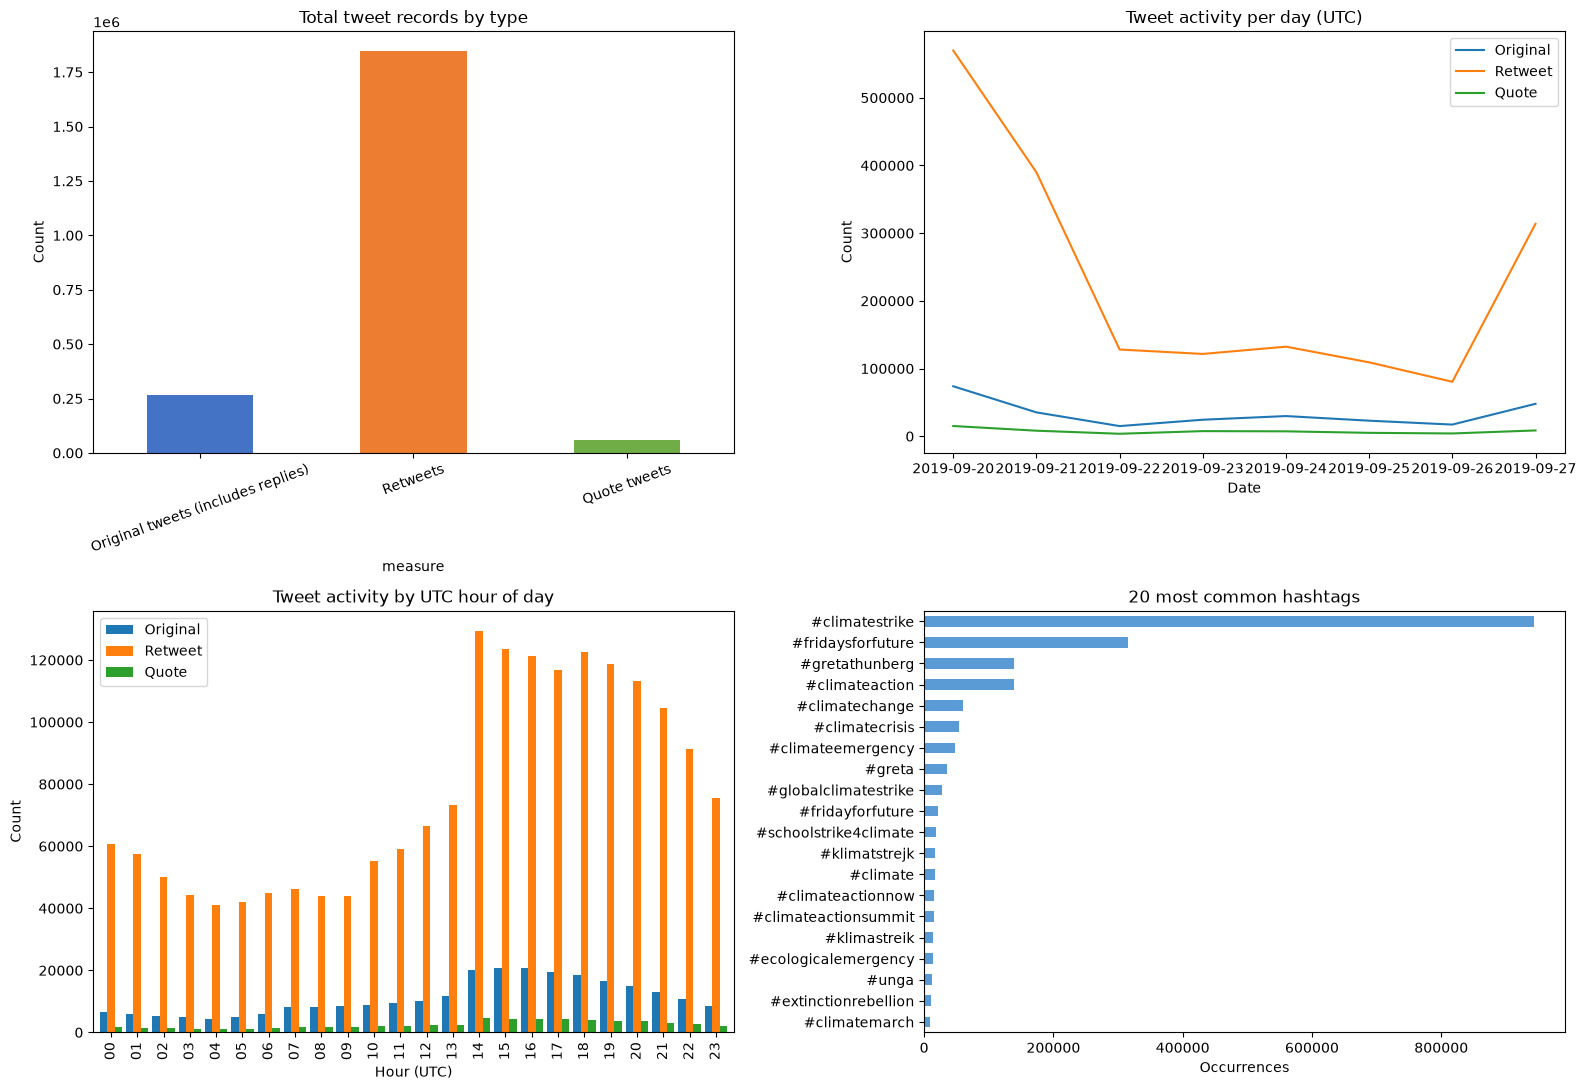

Top 20 hashtags:


,hashtag,count
0,climatestrike,943656
1,fridaysforfuture,314903
2,gretathunberg,139440
3,climateaction,138354
4,climatechange,60369
5,climatecrisis,53383
6,climateemergency,48487
7,greta,34956
8,globalclimatestrike,27551
9,fridayforfuture,21672


In [18]:
summary = pd.DataFrame([{'measure':'Unique users','count':user_count}, {'measure':'All tweet records','count':records_seen}, {'measure':'Original tweets (includes replies)','count':type_counts['original_tweets']}, {'measure':'Retweets','count':type_counts['retweets']}, {'measure':'Quote tweets','count':type_counts['quotes']}, {'measure':'Replies (subset of originals)','count':replies_seen}, {'measure':'Hashtag occurrences','count':sum(hashtag_counts.values())}, {'measure':'Distinct hashtags (case-insensitive)','count':len(hashtag_counts)}])
display(summary)
categories = ['original_tweets','retweets','quotes']
daily_summary = pd.DataFrame.from_dict({day: dict(counts) for day,counts in daily_counts.items()}, orient='index').fillna(0).sort_index().reindex(columns=categories, fill_value=0)
hourly_summary = pd.DataFrame.from_dict({hour: dict(counts) for hour,counts in hour_of_day_counts.items()}, orient='index').fillna(0).reindex([f'{h:02d}' for h in range(24)], fill_value=0).reindex(columns=categories, fill_value=0)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
summary.iloc[2:5].set_index('measure')['count'].plot(kind='bar', ax=axes[0,0], color=['#4472C4','#ED7D31','#70AD47'])
axes[0,0].set_title('Total tweet records by type'); axes[0,0].set_ylabel('Count'); axes[0,0].tick_params(axis='x', rotation=20)
daily_summary.plot(ax=axes[0,1], linewidth=1.5); axes[0,1].set_title('Tweet activity per day (UTC)'); axes[0,1].set_xlabel('Date'); axes[0,1].set_ylabel('Count'); axes[0,1].legend(['Original','Retweet','Quote'])
hourly_summary.plot(kind='bar', ax=axes[1,0], width=0.85); axes[1,0].set_title('Tweet activity by UTC hour of day'); axes[1,0].set_xlabel('Hour (UTC)'); axes[1,0].set_ylabel('Count'); axes[1,0].legend(['Original','Retweet','Quote'])
top_hashtags = pd.Series(hashtag_counts, name='count').sort_values(ascending=False).head(20).sort_values()
top_hashtags.rename(index=lambda tag: '#' + tag).plot(kind='barh', ax=axes[1,1], color='#5B9BD5'); axes[1,1].set_title('20 most common hashtags'); axes[1,1].set_xlabel('Occurrences')
fig.tight_layout(); plt.show()
print('Top 20 hashtags:')
display(top_hashtags.sort_values(ascending=False).rename_axis('hashtag').reset_index())


## Filtering the data

This section shows how to cut the derived datasets down to the part you want to study. All filters live in `filters.py` (next to this notebook) and work on the files built above:

- `original_tweets.csv`: one original tweet per row (includes replies, excludes retweets and quotes)
- `retweet_events.csv`: one row per retweet, with exact time and the retweeted tweet
- `retweet_network_edges.csv`: one row per retweeting account → retweeted account pair
- `retweet_network_nodes.csv`: one row per account in the retweet network

A filter takes criteria and returns the matching **rows**; it does not compute summaries (those are in the summary section). Criteria given together are combined with AND.

In [22]:
from filters import *

retweet_nodes = load_nodes(NODES_CSV)
retweet_edges = load_edges(EDGES_CSV)
original_tweet_sample = next(iter_originals(ORIGINALS_CSV)).head(10)

print('Original tweets (first rows):'); display(original_tweet_sample)
print('Retweet events (first rows):'); display(pd.read_csv(EVENTS_CSV, nrows=5))
print('Retweet network edges (first rows):'); display(retweet_edges.head(10))
print('Retweet network nodes (first rows):'); display(retweet_nodes.head(10))
print(f'Edge rows: {len(retweet_edges):,}; node rows: {len(retweet_nodes):,}')

Original tweets (first rows):


,tweet_id,author_id,created_at,text,lang,conversation_id,reply_to_tweet_id,retweet_count,reply_count,like_count,quote_count,possibly_sensitive,hashtags
0,1174837416898596867,1072955978591563776,2019-09-20T00:07:22.000Z,@albertoclaveria @iresimpsonsfans #ClimateStri...,qme,1174443763596517386,1174444183618240513,0,0,0,0,False,climatestrike gretathunberg climatechangehoax
1,1174838632496033792,3022862503,2019-09-20T00:12:12.000Z,#ClimateHoax https://t.co/g1uC27Krt2,qht,1174838632496033792,NaN,0,0,0,0,False,climatehoax
2,1174838703992332288,786677101365723136,2019-09-20T00:12:29.000Z,@CBSNews #Idiots \n#ClimateScam,qme,1174625057483702272,1174625057483702272,0,1,1,0,False,idiots climatescam
3,1174839596754046977,1031890039612076034,2019-09-20T00:16:01.000Z,#ClimateEmergency #ClimateConfessions I’m goin...,en,1174839596754046977,NaN,0,1,1,0,False,climateemergency climateconfessions climatestr...
4,1174839932923330560,1069140295,2019-09-20T00:17:22.000Z,All this nonsense about #ClimateConfessions is...,en,1174839932923330560,NaN,0,0,1,0,False,climateconfessions climatechange globalwarming...
5,1174840528778780673,1069140295,2019-09-20T00:19:44.000Z,@DrMartyFox #ClimateChangeHoax https://t.co/Nj...,qme,1174669886016118790,1174669886016118790,0,0,1,0,False,climatechangehoax
6,1174841577333755910,1069140295,2019-09-20T00:23:54.000Z,@NikolovScience @JSegor @jimdtweet @Kenneth727...,qme,1051199957976444929,1174319689524056064,0,1,0,1,False,climatechangehoax
7,1174842101982539776,1069140295,2019-09-20T00:25:59.000Z,@DrMartyFox #ClimateChangeHoax https://t.co/48...,qme,1174483178318381057,1174483178318381057,0,0,0,0,False,climatechangehoax
8,1174843444646359045,895814938995957760,2019-09-20T00:31:19.000Z,@AndreVanDelft Saluti please find the unroll h...,en,1174706185397837824,1174843078156402688,1,0,0,0,False,qanon climatehoax
9,1174843716642705408,262800088,2019-09-20T00:32:24.000Z,"@charliekirk11 Apparently, #GretaThunberg's bo...",en,1174837629759541249,1174837629759541249,32,5,25,4,False,gretathunberg climateconfession climate hypocr...


Retweet events (first rows):


,retweet_id,created_at,source_account_id,target_account_id,target_tweet_id,target_from_mention
0,1174836630437470208,2019-09-20T00:04:14.000Z,1252004226,948976310466080768,1174825332018487296,1
1,1174836838588211200,2019-09-20T00:05:04.000Z,1171423782612783104,1004694289,1174805425075736577,1
2,1174846030401200128,2019-09-20T00:41:35.000Z,1166160314334928897,262800088,1174843716642705408,0
3,1174847370795900929,2019-09-20T00:46:55.000Z,63826026,19242147,1174508882053533698,1
4,1174848912999366656,2019-09-20T00:53:03.000Z,45478749,895814938995957760,1174843444646359045,0


Retweet network edges (first rows):


,source_account_id,target_account_id,unresolved_target_tweet_id,retweet_count,distinct_tweets_retweeted,retweets_target_from_mention,first_retweeted_at,last_retweeted_at
0,1000000043833810945,1006419421244678144,NaN,1,1,0,2019-09-26T18:34:24.000Z,2019-09-26T18:34:24.000Z
1,1000001515472474112,29417177,NaN,1,1,0,2019-09-21T08:51:35.000Z,2019-09-21T08:51:35.000Z
2,1000001979060576256,189631331,NaN,1,1,0,2019-09-20T17:36:39.000Z,2019-09-20T17:36:39.000Z
3,1000001979060576256,261119379,NaN,1,1,0,2019-09-20T17:36:30.000Z,2019-09-20T17:36:30.000Z
4,1000001979060576256,964066691545169920,NaN,1,1,1,2019-09-20T20:29:51.000Z,2019-09-20T20:29:51.000Z
5,1000002497363283969,14159148,NaN,1,1,0,2019-09-23T01:23:42.000Z,2019-09-23T01:23:42.000Z
6,1000003055717363712,1006419421244678144,NaN,1,1,0,2019-09-27T11:27:42.000Z,2019-09-27T11:27:42.000Z
7,1000003055717363712,1027122188896428032,NaN,1,1,0,2019-09-27T14:55:22.000Z,2019-09-27T14:55:22.000Z
8,1000003055717363712,1085976335158337536,NaN,1,1,0,2019-09-27T14:48:52.000Z,2019-09-27T14:48:52.000Z
9,1000003055717363712,130881030,NaN,1,1,0,2019-09-27T20:15:13.000Z,2019-09-27T20:15:13.000Z


Retweet network nodes (first rows):


,account_id,tweets_in_source,first_seen,last_seen,retweets_sent,retweets_received,original_tweets,likes_on_originals,replies_on_originals,quotes_on_originals,retweet_counter_on_originals
0,1000000043833810945,1,2019-09-26T18:34:24.000Z,2019-09-26T18:34:24.000Z,1,0,0,0,0,0,0
1,1000001291945500672,1,2019-09-27T07:28:12.000Z,2019-09-27T07:28:12.000Z,0,541,1,2652,12,43,701
2,1000001515472474112,1,2019-09-21T08:51:35.000Z,2019-09-21T08:51:35.000Z,1,0,0,0,0,0,0
3,1000001979060576256,6,2019-09-20T17:36:30.000Z,2019-09-20T20:29:51.000Z,3,8,3,23,1,1,8
4,1000002497363283969,9,2019-09-23T01:23:42.000Z,2019-09-27T22:42:16.000Z,1,17,8,65,2,1,16
5,1000003055717363712,9,2019-09-26T16:10:58.000Z,2019-09-27T20:15:13.000Z,6,0,3,0,0,0,0
6,1000004593990979584,1,2019-09-27T13:18:02.000Z,2019-09-27T13:18:02.000Z,1,0,0,0,0,0,0
7,1000004724987518981,1,2019-09-27T07:04:53.000Z,2019-09-27T07:04:53.000Z,1,0,0,0,0,0,0
8,1000004822194585600,1,2019-09-24T14:11:52.000Z,2019-09-24T14:11:52.000Z,1,0,0,0,0,0,0
9,1000006219690541058,1,2019-09-20T23:26:20.000Z,2019-09-20T23:26:20.000Z,1,0,0,0,0,0,0


Edge rows: 1,531,425; node rows: 757,752


### Filter original tweets

Every call to `filter_originals(path, ...)` scans `original_tweets.csv` and returns a DataFrame with the matching tweets.

In [20]:
# 1) one hashtag, or several (match="any" = OR, "all" = AND). Case-insensitive, whole-tag match.
hoax   = filter_originals(ORIGINALS_CSV, hashtags="climatehoax")
either = filter_originals(ORIGINALS_CSV, hashtags=["climatehoax", "climatescam"], match="any")
both   = filter_originals(ORIGINALS_CSV, hashtags=["climatehoax", "climatescam"], match="all")
print(f'#climatehoax: {len(hoax):,} | hoax OR scam: {len(either):,} | hoax AND scam: {len(both):,}')

# 2) by day / by hour window (UTC, both ends inclusive)
one_day   = filter_originals(ORIGINALS_CSV, start='2019-09-20', end='2019-09-20')
afternoon = filter_originals(ORIGINALS_CSV, start='2019-09-20 14', end='2019-09-20 17')
print(f'20 Sep: {len(one_day):,} | 20 Sep 14:00-17:59: {len(afternoon):,}')

# 3) language, replies, engagement, author, text pattern
english    = filter_originals(ORIGINALS_CSV, lang='en')
no_replies = filter_originals(ORIGINALS_CSV, replies='exclude')       # or replies='only'
popular    = filter_originals(ORIGINALS_CSV, min_likes=100)           # also min_retweets / min_replies / min_quotes
greta      = filter_originals(ORIGINALS_CSV, text_regex=r'\bgreta\b') # regex on the text
someone    = filter_originals(ORIGINALS_CSV, authors=[original_tweet_sample['author_id'].iloc[0]])
print(f'english: {len(english):,} | no replies: {len(no_replies):,} | >=100 likes: {len(popular):,} | mention greta: {len(greta):,} | one author: {len(someone):,}')

# 4) combine any criteria (they are ANDed)
combo = filter_originals(ORIGINALS_CSV, hashtags=['climatehoax', 'climatescam'], lang='en',
                         start='2019-09-20', end='2019-09-22', replies='exclude', min_likes=1)
display(combo[['created_at', 'author_id', 'text', 'like_count', 'retweet_count']].head())

# 5) save a filtered subset to its own CSV, streamed (safe for big results)
n = filter_originals_to_csv(ORIGINALS_CSV.parent / 'subset_skeptic_en.csv', ORIGINALS_CSV,
                            hashtags=['climatehoax', 'climatescam', 'climatehysteria'], lang='en')
print(f'saved {n:,} tweets')

#climatehoax: 2,877 | hoax OR scam: 3,252 | hoax AND scam: 49
20 Sep: 73,814 | 20 Sep 14:00-17:59: 38,391
english: 178,966 | no replies: 219,576 | >=100 likes: 4,796 | mention greta: 20,167 | one author: 9


,created_at,author_id,text,like_count,retweet_count
0,2019-09-20T00:16:01.000Z,1031890039612076034,#ClimateEmergency #ClimateConfessions I’m goin...,1,0
1,2019-09-20T03:36:00.000Z,79932564,If you #ClimateStrike you are the dumbest cunt...,1,0
2,2019-09-20T09:52:56.000Z,243393079,"Obviously, there is no connection between thes...",1,2
3,2019-09-20T10:40:09.000Z,37543877,If the climate change hysteria and Green New D...,1,0
4,2019-09-20T10:46:52.000Z,2415436170,"In 2006 Al Gore released his movie ""An Inconve...",1,0


saved 2,835 tweets


### Filter the retweet network

Edges point from the account that **retweeted** (`source_account_id`) to the account that was **retweeted** (`target_account_id`). As the example we take the account pair with the most retweets (`A` retweets `B`).

1. **Between two accounts**: `retweets_between` returns the aggregated edge row(s); `count_retweets_between` sums `retweet_count`; `both_directions=True` also counts B retweeting A. For counts at an exact day or hour use `filter_events` / `count_events` on the events table.
2. **Time window on edges**: `edges_in_window` has two modes. `'overlap'` keeps pairs with at least one retweet in the window, but their `retweet_count` is still the pair's total over the whole period. `'contained'` keeps only pairs whose retweets are all inside the window, so counts are exact for that window but pairs spreading beyond it are left out.
3. **Around one account**: `retweets_of_account` with `role='sent'`, `'received'` or `'both'` (optionally with a time window), and `ego_network` for all edges among the account and its neighbours within `hops` steps.
4. **Subsets of the network**: `min_weight_pairs` keeps ties with at least `k` retweets; `unresolved_edges` returns retweets whose original author is unknown; `filter_nodes` selects accounts by activity; `edges_among` keeps only edges whose two ends are both in a given list of accounts.
5. **Retweets and themes**: `retweets_by_hashtag` returns the retweets of original tweets that contain given hashtags, optionally only those made in a time window. It links the events table to the tweet table.

In [ ]:
import importlib, filters
importlib.reload(filters)
from filters import *

print(filters.__file__)
print('count_events' in dir(filters))

import filters
print(filters.__file__)
print('count_events' in dir(filters), 'count_events' in filters.__all__)

c:\Users\oskar\OneDrive\Documents\Kool\Uppsala\S3\Mining of Social Data\Mining-of-Social-Data\Lab1\filters.py
True


In [25]:
# the account pair with the most retweets is a more informative example than an arbitrary edge
top_pair = pair_weights(retweet_edges).iloc[0]
A, B = top_pair['source_account_id'], top_pair['target_account_id']

# 1) retweets between two accounts (one direction, or both)
display(retweets_between(retweet_edges, A, B))
print('A retweeted B (whole period):', count_retweets_between(retweet_edges, A, B))
print('A<->B either way:', count_retweets_between(retweet_edges, A, B, both_directions=True))

# ...and at an exact day / hour, from the retweet-level file
print('A retweeted B on 22 Sep:', count_events(EVENTS_CSV, source=A, target=B, start='2019-09-22', end='2019-09-22'))
display(filter_events(EVENTS_CSV, source=A, target=B, start='2019-09-22 12', end='2019-09-22 18').head())

# 2) time window on the aggregated edges: 'overlap' = some retweet in the window (count is the pair total);
#    'contained' = all of the pair's retweets are inside the window (count is exact)
day  = edges_in_window(retweet_edges, '2019-09-23', '2019-09-23', mode='contained')
span = edges_in_window(retweet_edges, '2019-09-23', '2019-09-25')
print(f'edges fully inside 23 Sep: {len(day):,} | edges active between 23 and 25 Sep: {len(span):,}')

# 3) everything around one account
sent     = retweets_of_account(retweet_edges, B, role='sent')
received = retweets_of_account(retweet_edges, B, role='received', start='2019-09-20', end='2019-09-22')
ego      = ego_network(retweet_edges, B, hops=1)
print(f'B sent {len(sent):,} edges | received (20-22 Sep) {len(received):,} | 1-hop ego network {len(ego):,} edges')

# 4) strong ties, retweets whose original author is unknown, sub-networks of busy accounts
strong         = min_weight_pairs(retweet_edges, k=10)         # source retweeted target >= 10 times
missing_source = unresolved_edges(retweet_edges)               # original author unknown
busy           = filter_nodes(retweet_nodes, min_received=500) # accounts retweeted >= 500 times
core           = edges_among(retweet_edges, busy['account_id'])# only edges between those accounts
print(f'strong ties: {len(strong):,} | unresolved: {len(missing_source):,} | busy accounts: {len(busy):,} | edges among them: {len(core):,}')

# 5) retweets of tweets that carry a hashtag (optionally only retweets made in a time window)
tags = ['climatehoax', 'climatescam']
rts_all = retweets_by_hashtag(tags, originals_path=ORIGINALS_CSV, events_path=EVENTS_CSV)
rts_22  = retweets_by_hashtag(tags, originals_path=ORIGINALS_CSV, events_path=EVENTS_CSV, start='2019-09-22', end='2019-09-22')
print(f'retweets of #climatehoax / #climatescam tweets: {len(rts_all):,} (made on 22 Sep: {len(rts_22):,})')

,source_account_id,target_account_id,unresolved_target_tweet_id,retweet_count,distinct_tweets_retweeted,retweets_target_from_mention,first_retweeted_at,last_retweeted_at
466483,204009016,2518143973,NaN,174,174,10,2019-09-20T16:44:44.000Z,2019-09-27T22:34:58.000Z


A retweeted B (whole period): 174
A<->B either way: 174
A retweeted B on 22 Sep: 6


,retweet_id,created_at,source_account_id,target_account_id,target_tweet_id,target_from_mention
0,1175813466608820225,2019-09-22T16:45:50.000Z,204009016,2518143973,1175727979495862272,0
1,1175814177736265728,2019-09-22T16:48:40.000Z,204009016,2518143973,1175787497969917952,0
2,1175814382858768386,2019-09-22T16:49:29.000Z,204009016,2518143973,1175791977931165698,0
3,1175814675386314753,2019-09-22T16:50:38.000Z,204009016,2518143973,1175728114288209920,0
4,1175815226895343616,2019-09-22T16:52:50.000Z,204009016,2518143973,1175789093839626246,0


edges fully inside 23 Sep: 93,576 | edges active between 23 and 25 Sep: 348,400
B sent 97 edges | received (20-22 Sep) 2,853 | 1-hop ego network 23,494 edges
strong ties: 4,717 | unresolved: 9,093 | busy accounts: 436 | edges among them: 1,327
retweets of #climatehoax / #climatescam tweets: 2,800 (made on 22 Sep: 405)


### Linking a theme to the network

This connects the two datasets. First we find the authors of tweets using #climatehoax or #climatescam, then `edges_among` keeps only the retweet edges between those accounts. The result is the retweet network *inside* that group of accounts. The same pattern works for any theme or account group, for example by swapping the hashtag list or the account list.

In [26]:
# accounts that wrote a #climatehoax / #climatescam tweet, and who retweeted whom among them
authors_hoax = filter_originals(ORIGINALS_CSV, hashtags=['climatehoax', 'climatescam'])['author_id'].unique()
hoax_net = edges_among(retweet_edges, authors_hoax)
print(f'{len(authors_hoax):,} accounts, {len(hoax_net):,} retweet edges among them')

1,625 accounts, 360 retweet edges among them


## Task 2: Classifying accounts

The file contains no account profile data (see Task 1), so accounts can only be grouped by **what they do** (tweet, retweet, get retweeted, language) and **what they say** (hashtags, text). The table lists candidate classification systems.

| Classification | Groups | Question it lets us ask | Based on | Main weaknesses |
|---|---|---|---|---|
| **Stance by hashtag use** | activist-leaning / sceptic-leaning / mixed / none | Do the two camps talk about different themes, receive different attention, form separate retweet communities? | hashtags in an account's own original tweets (sceptic vs activist hashtag lists from the lab description) | a hashtag is not a stance (irony, quoting, activists using #climatehoax to mock it); covers only accounts with original tweets |
| **Role in the retweet network** | source (mostly retweeted) / amplifier (mostly retweets others) / mixed / low activity | Who produces content that spreads, and who spreads it? | retweets sent vs received (node table) | thresholds are arbitrary; retweets whose original author is unknown are not counted as received |
| **Human vs automated (activity flag)** | high-volume / ordinary | Is amplification driven by a few very active accounts? | tweets per account during the week; later: posting-time regularity, share of retweets | volume is not automation (activists, organisations and news accounts also post a lot); no profile data to confirm |
| **Language / national community** | e.g. English, Swedish, German, other | Do national movements interact or stay separate? | `lang`, language-specific hashtags such as #klimatstrejk, #klimastreik | `lang` contains pseudo-codes (`qme`, `qht`); multilingual accounts |
| **Influence tiers** | e.g. top 0.1% / top 1% / rest by retweets received | How concentrated is attention? | `retweets_received` | heavy-tailed; one viral tweet can dominate |
| **Structural communities** | found by an algorithm (e.g. Louvain) | Which groups emerge from retweeting behaviour alone, and do they match stance or language? | the retweet graph | needs graph tooling; later in the course |

**Ethics note.** The labels describe real, identifiable accounts and can be wrong (a "sceptic" label from a hashtag, a "bot" label from volume). We treat them as noisy group-level variables for aggregate analysis and do not report labels for individual accounts.

In [27]:
import numpy as np

# hashtag lists: taken from the search terms in the lab description; edit after the group discussion
SKEPTIC_TAGS = ['climatehoax', 'climatechangehoax', 'climatescam', 'climatecult', 'climatehysteria', 'netzerononsense',
                'climatealarmism', 'globalwarmingfraud', 'climateconspiracy', 'climatefraud', 'crap25', 'crap27',
                'climatehypocrisy', 'gretathunbergexposed', 'noclimateemergency']
ACTIVIST_TAGS = ['fridaysforfuture', 'climatestrike', 'globalclimatestrike', 'schoolstrike4climate', 'extinctionrebellion',
                 'climatecrisis', 'climateemergency', 'actonclimate', 'timeforaction', 'climateactionnow', 'climatemarch']

# 1) stance by hashtag use: count each author's original tweets with sceptic / activist hashtags
parts = []
for chunk in iter_originals(ORIGINALS_CSV):
    flags = pd.DataFrame({'author_id': chunk['author_id'],
                          'skeptic_tweets': hashtags_in(chunk, SKEPTIC_TAGS).astype(int),
                          'activist_tweets': hashtags_in(chunk, ACTIVIST_TAGS).astype(int),
                          'original_tweets_n': 1})
    parts.append(flags.groupby('author_id').sum())
stance = pd.concat(parts).groupby(level=0).sum()
stance['hashtag_stance'] = np.select(
    [stance.skeptic_tweets > stance.activist_tweets,
     stance.activist_tweets > stance.skeptic_tweets,
     (stance.skeptic_tweets == stance.activist_tweets) & (stance.skeptic_tweets > 0)],
    ['skeptic-leaning', 'activist-leaning', 'mixed'], default='no stance hashtag')
stance = stance.reset_index().rename(columns={'author_id': 'account_id'})
stance['account_id'] = stance['account_id'].astype(str)

# 2) role in the retweet network + 3) high-volume flag, from the node table
roles = retweet_nodes[['account_id', 'tweets_in_source', 'retweets_sent', 'retweets_received']].copy()
roles['account_id'] = roles['account_id'].astype(str)
activity = roles['retweets_sent'] + roles['retweets_received']
share_received = roles['retweets_received'] / activity.where(activity > 0)
roles['network_role'] = np.select(
    [activity < 5, share_received >= 0.8, share_received <= 0.2],
    ['low activity (<5 retweets)', 'source (mostly retweeted)', 'amplifier (mostly retweets)'], default='mixed')
roles['high_volume'] = roles['tweets_in_source'] >= 100        # starting value; look at the distribution before fixing it

account_groups = roles.merge(stance, on='account_id', how='outer')
account_groups['hashtag_stance'] = account_groups['hashtag_stance'].fillna('no original tweets')
account_groups['network_role'] = account_groups['network_role'].fillna('not in retweet network')
account_groups['high_volume'] = account_groups['high_volume'].eq(True)
account_groups.to_csv(OUT_DIR / 'account_groups.csv', index=False, encoding='utf-8-sig')

print(f'{len(account_groups):,} accounts classified (union of retweet-network accounts and authors of original tweets)\n')
print('Stance by hashtag use:'); display(account_groups['hashtag_stance'].value_counts().to_frame('accounts'))
print('Role in the retweet network:'); display(account_groups['network_role'].value_counts().to_frame('accounts'))
print(f"High-volume accounts (>= 100 tweet records): {int(account_groups['high_volume'].sum()):,}")
print('\nStance x network role (accounts):')
display(pd.crosstab(account_groups['hashtag_stance'], account_groups['network_role']))

823,726 accounts classified (union of retweet-network accounts and authors of original tweets)

Stance by hashtag use:


,accounts
hashtag_stance,
no original tweets,678688
activist-leaning,108605
no stance hashtag,33753
skeptic-leaning,2372
mixed,308


Role in the retweet network:


,accounts
network_role,
low activity (<5 retweets),668776
not in retweet network,65974
amplifier (mostly retweets),63005
source (mostly retweeted),17059
mixed,8912


High-volume accounts (>= 100 tweet records): 779

Stance x network role (accounts):


network_role,amplifier (mostly retweets),low activity (<5 retweets),mixed,not in retweet network,source (mostly retweeted)
hashtag_stance,,,,,
activist-leaning,7611,36468,6634,46127,11765
mixed,19,100,14,154,21
no original tweets,53889,621116,1191,0,2492
no stance hashtag,1351,10192,983,18576,2651
skeptic-leaning,135,900,90,1117,130


### Reading the result

- The stance label comes from an account's own original tweets and the role label from the retweet network, so many accounts have only one of them; `no original tweets` and `not in retweet network` mark the missing side.
- The cross-table shows how the groups relate, for example whether sceptic-leaning accounts are mostly sources or amplifiers. Treat it as a first look: the hashtag lists and role thresholds are choices the group should agree on and justify.
- Starting values to revisit after looking at the distributions: at least 5 retweets for a role, at least 80% / at most 20% received for source / amplifier, and at least 100 tweet records for the high-volume flag.